In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("country1.csv")
df

,country,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits"
0,AFG,33.70269,34.53602,34.53602
1,AGO,64.57157,65.32993,64.99177
2,ALB,52.60171,52.67715,52.64734
3,ARE,86.51006,89.75407,86.52729
4,ARG,48.96341,56.44015,49.26822
...,...,...,...,...
186,XKX,50.29844,55.28702,52.87432
187,YEM,0.00000,0.00000,0.00000
188,ZAF,68.26741,68.32331,68.24925
189,ZMB,71.10859,72.09460,71.72488


In [3]:
df.drop('country',axis=1,inplace=True)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 191 entries, 0 to 190
Data columns (total 3 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   fy2017, Dealing with construction permits  191 non-null    float64
 1   fy2019, Dealing with construction permits  191 non-null    float64
 2   fy2018, Dealing with construction permits  191 non-null    float64
dtypes: float64(3)
memory usage: 4.6 KB


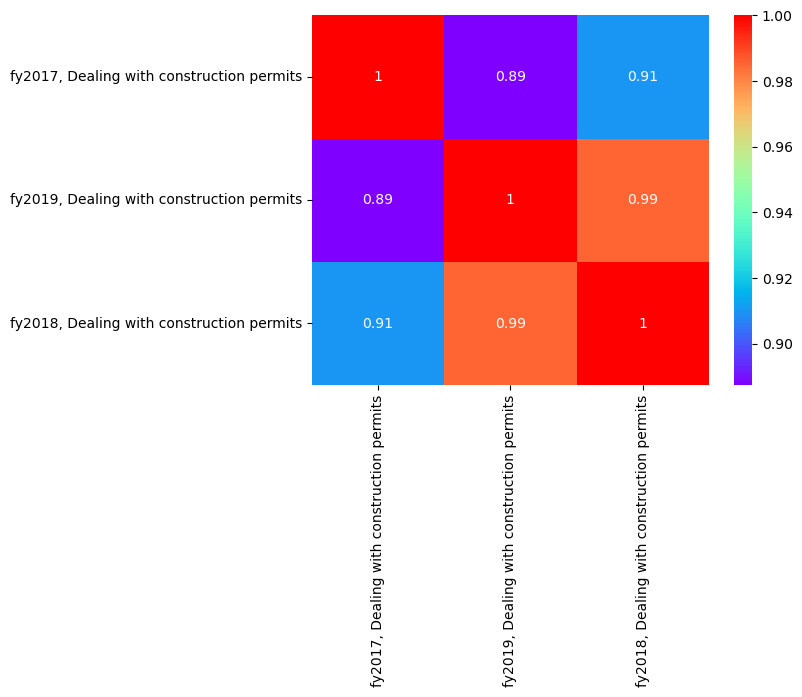

In [8]:
sns.heatmap(df.corr(),annot=True,cmap='rainbow')
plt.show()

In [10]:
from sklearn.preprocessing import MinMaxScaler
mm=MinMaxScaler()
data=mm.fit_transform(df)
data

array([[0.36950644, 0.36949953, 0.37851406],
       [0.70794382, 0.69896237, 0.71230844],
       [0.57670977, 0.56359077, 0.57701375],
       [0.94847101, 0.96027529, 0.94833729],
       [0.53682052, 0.60385096, 0.53997866],
       [0.74303218, 0.78159697, 0.74512985],
       [0.71812428, 0.70331171, 0.71883072],
       [0.92523267, 0.9066613 , 0.92712359],
       [0.82227073, 0.80376565, 0.82287085],
       [0.6631289 , 0.78485277, 0.80123442],
       [0.57915051, 0.58855059, 0.62261066],
       [0.82617447, 0.80726421, 0.82656841],
       [0.76938915, 0.75469797, 0.77088514],
       [0.74780424, 0.7348393 , 0.748423  ],
       [0.66414567, 0.65320794, 0.66655086],
       [0.82251073, 0.81233616, 0.82704517],
       [0.80830746, 0.88938184, 0.80449721],
       [0.77319882, 0.75857655, 0.77699062],
       [0.5325245 , 0.51966533, 0.53234339],
       [0.76993076, 0.80431108, 0.81953331],
       [0.70382607, 0.68779512, 0.70319566],
       [0.65587673, 0.64234465, 0.65713163],
       [0.

In [12]:
df2=pd.DataFrame(data=data,columns=df.columns)
df2

,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits"
0,0.369506,0.369500,0.378514
1,0.707944,0.698962,0.712308
2,0.576710,0.563591,0.577014
3,0.948471,0.960275,0.948337
4,0.536821,0.603851,0.539979
...,...,...,...
186,0.551457,0.591514,0.579501
187,0.000000,0.000000,0.000000
188,0.748464,0.730988,0.748010
189,0.779614,0.771337,0.786103


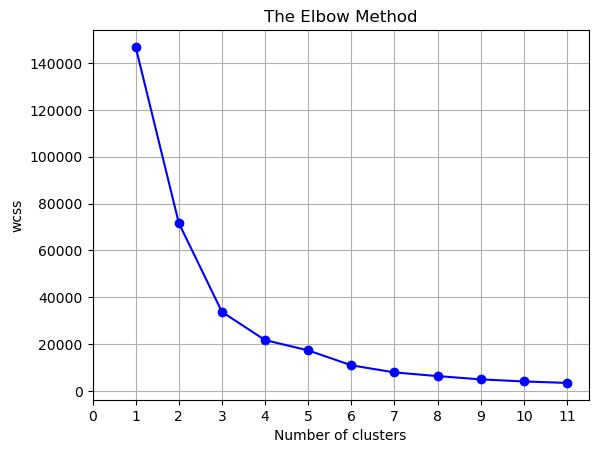

In [18]:
import warnings 
warnings.filterwarnings('ignore')
from sklearn.cluster import KMeans
wcss=[]
for i in range (1,12):
    kmeans=KMeans(n_clusters=i,random_state=0)
    kmeans.fit(df)
    wcss.append(kmeans.inertia_)
plt.plot(range(1,12),wcss,marker='o',linestyle='-',color='b')
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('wcss')
plt.xticks(np.linspace(0,11,12,dtype=int))
plt.grid()
plt.show()
    

In [20]:
from sklearn.cluster import KMeans
model=KMeans(n_clusters=3,random_state=42)
model.fit(df2)

KMeans(n_clusters=3, random_state=42)

In [21]:
label=model.labels_
label

array([0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0,
       0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 0, 0, 1, 1, 1, 1, 0, 2, 2, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1,
       2, 1, 0, 1, 1, 0, 1, 1, 1, 1, 2, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 2, 1, 1, 0])

In [23]:
from collections import Counter
Counter(label)

Counter({1: 120, 0: 65, 2: 6})

In [24]:
df2['Label']=model.labels_
df2

,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits",Label
0,0.369506,0.369500,0.378514,0
1,0.707944,0.698962,0.712308,1
2,0.576710,0.563591,0.577014,0
3,0.948471,0.960275,0.948337,1
4,0.536821,0.603851,0.539979,0
...,...,...,...,...
186,0.551457,0.591514,0.579501,0
187,0.000000,0.000000,0.000000,2
188,0.748464,0.730988,0.748010,1
189,0.779614,0.771337,0.786103,1


In [25]:
df1=pd.read_csv('country1.csv')
df1

,country,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits"
0,AFG,33.70269,34.53602,34.53602
1,AGO,64.57157,65.32993,64.99177
2,ALB,52.60171,52.67715,52.64734
3,ARE,86.51006,89.75407,86.52729
4,ARG,48.96341,56.44015,49.26822
...,...,...,...,...
186,XKX,50.29844,55.28702,52.87432
187,YEM,0.00000,0.00000,0.00000
188,ZAF,68.26741,68.32331,68.24925
189,ZMB,71.10859,72.09460,71.72488


In [26]:
df1['Label']=model.labels_
df1

,country,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits",Label
0,AFG,33.70269,34.53602,34.53602,0
1,AGO,64.57157,65.32993,64.99177,1
2,ALB,52.60171,52.67715,52.64734,0
3,ARE,86.51006,89.75407,86.52729,1
4,ARG,48.96341,56.44015,49.26822,0
...,...,...,...,...,...
186,XKX,50.29844,55.28702,52.87432,0
187,YEM,0.00000,0.00000,0.00000,2
188,ZAF,68.26741,68.32331,68.24925,1
189,ZMB,71.10859,72.09460,71.72488,1


In [27]:
performance_metrics=['fy2017, Dealing with construction permits','fy2019, Dealing with construction permits','fy2018, Dealing with construction permits']
cluster_summary=df1.groupby('Label')[performance_metrics].agg(['mean','min','max'])
print(cluster_summary)

      fy2017, Dealing with construction permits                    \
                                           mean     min       max   
Label                                                               
0                                     51.370824   0.000  62.32173   
1                                     72.636481  60.484  91.21002   
2                                      4.823087   0.000  28.93852   

      fy2019, Dealing with construction permits                      \
                                           mean       min       max   
Label                                                                 
0                                     56.480015  34.09510  83.51370   
1                                     73.969857  64.13486  93.46702   
2                                      4.823087   0.00000  28.93852   

      fy2018, Dealing with construction permits                      
                                           mean       min       max  
Label             

In [28]:
highly_economic=df1[df1['Label']==1]
average_economic=df1[df1['Label']==0]
low_economic=df1[df1['Label']==2]

In [29]:
print(highly_economic.shape[0])
print(average_economic.shape[0])
print(low_economic.shape[0])

120
65
6


In [30]:
highly_economic['country']

1      AGO
3      ARE
5      ARM
6      ATG
7      AUS
      ... 
181    VCT
183    VNM
185    WSM
188    ZAF
189    ZMB
Name: country, Length: 120, dtype: object

In [31]:
low_economic['country']

50     ERI
96     LBR
97     LBY
154    SOM
164    SYR
187    YEM
Name: country, dtype: object

In [32]:
average_economic['country']

0      AFG
2      ALB
4      ARG
10     BDI
14     BGD
      ... 
180    UZB
182    VEN
184    VUT
186    XKX
190    ZWE
Name: country, Length: 65, dtype: object

In [34]:
from sklearn.metrics import silhouette_score
score=silhouette_score(df2,label)
score

0.8546944689134715

In [35]:
df2

,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits",Label
0,0.369506,0.369500,0.378514,0
1,0.707944,0.698962,0.712308,1
2,0.576710,0.563591,0.577014,0
3,0.948471,0.960275,0.948337,1
4,0.536821,0.603851,0.539979,0
...,...,...,...,...
186,0.551457,0.591514,0.579501,0
187,0.000000,0.000000,0.000000,2
188,0.748464,0.730988,0.748010,1
189,0.779614,0.771337,0.786103,1


In [36]:
X=df2.iloc[:,:-1]
y=df2.iloc[:,-1]

In [37]:
X

,"fy2017, Dealing with construction permits","fy2019, Dealing with construction permits","fy2018, Dealing with construction permits"
0,0.369506,0.369500,0.378514
1,0.707944,0.698962,0.712308
2,0.576710,0.563591,0.577014
3,0.948471,0.960275,0.948337
4,0.536821,0.603851,0.539979
...,...,...,...
186,0.551457,0.591514,0.579501
187,0.000000,0.000000,0.000000
188,0.748464,0.730988,0.748010
189,0.779614,0.771337,0.786103


In [38]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.80,random_state=42)

In [40]:
from sklearn.linear_model import LogisticRegression
clf=LogisticRegression()
clf.fit(X_train,y_train)

LogisticRegression()

In [42]:
y_pred=clf.predict(X_test)

In [43]:
from sklearn.metrics import *
accuracy_score(y_test,y_pred)

0.8461538461538461

In [44]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.85      0.73      0.79        15
           1       0.85      1.00      0.92        22
           2       0.00      0.00      0.00         2

    accuracy                           0.85        39
   macro avg       0.56      0.58      0.57        39
weighted avg       0.80      0.85      0.82        39

